In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Show one value per region: choose a view

With one value per brain region, iblatlas can colour the regions on a slice, a top view of the brain, the dorsal cortex flat map or the Swanson map. This page shows the input all four take, draws the same values on each, and links to a page for each view.

## The input

Each view takes an array of region acronyms and an array of values of the same length, one value per region. The acronyms must belong to the mapping passed to the plotting function, here Beryl; see [Brain region mappings](../explanation/brain-region-mappings.qmd). The values below are stand-ins, one for each Beryl region; replace `acronyms` and `values` with your own.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from iblatlas.atlas import AllenAtlas
from iblatlas.plots import plot_scalar_on_flatmap, plot_scalar_on_slice, plot_swanson_vector

ba = AllenAtlas()
br = ba.regions

# Stand-in values: one per Beryl region
acronyms = br.acronym[np.unique(br.mappings['Beryl'])]
acronyms = acronyms[~np.isin(acronyms, ['void', 'root'])]
values = np.random.default_rng(0).random(acronyms.size)

Acronyms finer than the mapping, such as cortical layers, convert to it with `acronym2acronym`:

In [3]:
br.acronym2acronym(['VISa1', 'VISa2/3', 'CA1'], mapping='Beryl')

array(['VISa', 'VISa', 'CA1'], dtype=object)

Several fine regions can convert to the same Beryl region, as the two VISa layers do here; combine their values before plotting.

## The four views

The same values on each view:

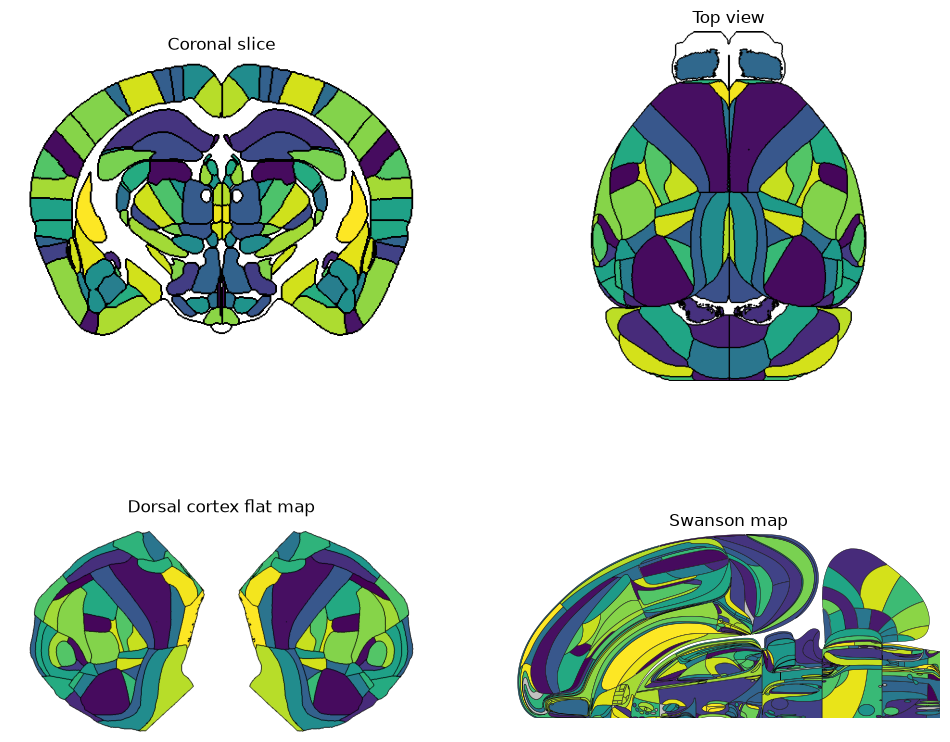

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

plot_scalar_on_slice(acronyms, values, coord=-2000, slice='coronal', mapping='Beryl',
                     hemisphere='both', background='boundary', brain_atlas=ba, ax=axs[0, 0])
plot_scalar_on_slice(acronyms, values, slice='top', mapping='Beryl',
                     hemisphere='both', background='boundary', brain_atlas=ba, ax=axs[0, 1])
plot_scalar_on_flatmap(acronyms, values, depth=0, mapping='Beryl',
                       hemisphere='both', background='boundary', ax=axs[1, 0])
plot_swanson_vector(acronyms, values, br=br, ax=axs[1, 1])

for ax, title in zip(axs.flat, ['Coronal slice', 'Top view', 'Dorsal cortex flat map', 'Swanson map']):
    ax.set_title(title)
    ax.set_axis_off()

- **Coronal slice**: one plane through the brain; coronal, sagittal and horizontal slices are on [Show one value per region on slices](plot-values-on-slices.ipynb).
- **Top view**: the region at the brain's surface at each position, seen from above; see [the top view section](plot-values-on-slices.ipynb#example-4-top-view) of the slices page.
- **Dorsal cortex flat map**: dorsal cortex only, flattened; other regions are not drawn. See [Show one value per region on the dorsal cortex flat map](plot-on-cortical-flatmap.ipynb).
- **Swanson map**: the whole brain on one flat map, drawn for a fixed set of regions. See [Show one value per region on the Swanson map](plot-on-swanson-flatmap.ipynb).

Regions outside the Swanson map's set stay grey. The number of stand-in Beryl regions that are not Swanson regions:

In [5]:
swanson_acronyms = br.acronym[np.unique(br.mappings['Swanson'])]
int((~np.isin(acronyms, swanson_acronyms)).sum())

44

To convert a region list to regions the Swanson map draws, see [Make a region list plottable on the Swanson map](make-regions-plottable-on-swanson.ipynb).

## Different values in each hemisphere

To show different values in each hemisphere, see [Show different values in each hemisphere](show-different-values-in-each-hemisphere.ipynb).